Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.analysis.cytosol import platereader as pr

# Set up plotting
pr.plot_setup()

## Load Data

In [2]:
# Specify file paths
data_file = "20260608-131856-cytation5-pure-timecourse-gfp-biotek-cdk.txt"
platemap_file = "1DNA-ClpX.csv"


# Load data
data, platemap = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek-cdk"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
data.head()

,Time,Temperature,Well,Data,Row,Column,Read,Plate,Clock Time,Reader,Name
0,0 days 00:00:16,37.00,A1,590445,A,1,GFP-Gext,Plate 1,2026-06-08 13:19:11,Cytation5,1.38 nM pT7-ClpX + Purified ClpP + Purified GF...
1,0 days 00:05:16,37.00,A1,536434,A,1,GFP-Gext,Plate 1,2026-06-08 13:24:11,Cytation5,1.38 nM pT7-ClpX + Purified ClpP + Purified GF...
2,0 days 00:10:16,37.00,A1,516188,A,1,GFP-Gext,Plate 1,2026-06-08 13:29:11,Cytation5,1.38 nM pT7-ClpX + Purified ClpP + Purified GF...
3,0 days 00:15:16,37.00,A1,507549,A,1,GFP-Gext,Plate 1,2026-06-08 13:34:11,Cytation5,1.38 nM pT7-ClpX + Purified ClpP + Purified GF...
4,0 days 00:20:16,37.00,A1,505696,A,1,GFP-Gext,Plate 1,2026-06-08 13:39:11,Cytation5,1.38 nM pT7-ClpX + Purified ClpP + Purified GF...


## Plot Raw Curves

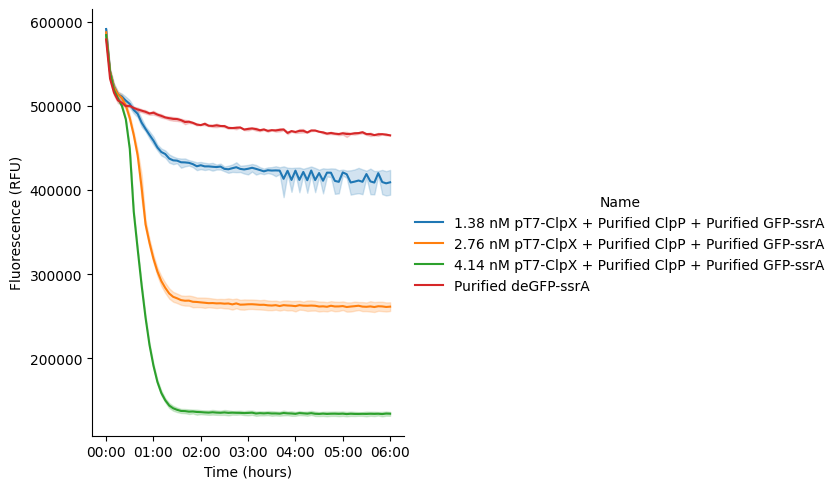

In [4]:
#| label: 20260608-clpx
g = pr.plot_curves(data=data)

## Normalize Data

In [5]:
data = pr.normalize_data_to_controls(data, ctrl_name = '10 uM HPTS')

Control name '10 uM HPTS' not found in data. No normalization applied.


Now replot your curves to see them normalized

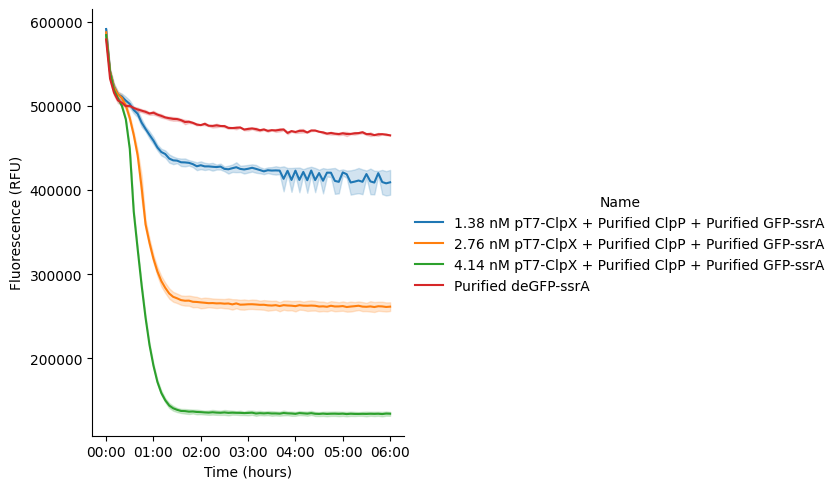

In [6]:
g = pr.plot_curves(data=data)

## Kinetic Analysis
**Metrics extracted:**

  - **Vmax** (`Velocity Max`): Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level and time to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit

In [7]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = pr.kinetic_analysis(
    data=data,
    group_by=['Well','Name'],  # Group by experimental condition
)

kinetics.head()

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


Velocity  \
                                                                             Time   
Well Name                                                                           
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 03:43:33.995054294   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 03:50:45.831992247   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 03:50:56.169552321   
A4   Purified deGFP-ssrA                                0 days 03:37:39.600247677   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 03:51:41.906055528   

                                                                             \
                                                             Data       Max   
Well Name                                                                     
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 297638.31 103581.32   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP... 291408.94 175062.36   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP... 286171.22 209496.79   
A4   Purified deGFP-ssrA                                292811.92  78129.62   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 301572.58 107175.05   

                                                                                Lag  \
                                                                               Time   
Well Name                                                                             
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP...   0 days 00:51:09.485743669   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP...   0 days 02:10:53.269093650   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP...   0 days 02:28:58.593644151   
A4   Purified deGFP-ssrA                                -1 days +23:52:47.625212018   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP...   0 days 01:02:52.110592238   

                                                                   \
                                                             Data   
Well Name                                                           
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 471841.95   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP... 257458.46   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP... 118317.72   
A4   Purified deGFP-ssrA                                533342.84   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 471847.50   

                                                                     Steady State  \
                                                                             Time   
Well Name                                                                           
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 07:57:23.383271142   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 06:17:48.199883751   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 05:51:35.920645362   
A4   Purified deGFP-ssrA                                0 days 09:08:42.748847149   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 0 days 08:00:15.188361292   

                                                                   \
                                                             Data   
Well Name                                                           
A1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 565512.79   
A2   2.76 nM pT7-ClpX + Purified ClpP + Purified GFP... 553676.99   
A3   4.14 nM pT7-ClpX + Purified ClpP + Purified GFP... 543725.32   
A4   Purified deGFP-ssrA                                556342.64   
B1   1.38 nM pT7-ClpX + Purified ClpP + Purified GFP... 572987.91   

                                                                                                       Fit  \
                                                                                                    params   
Well Name                                              

## Visualize Fits on Individual Wells

`Type` column not found in data. All data will be used for kinetic analysis.


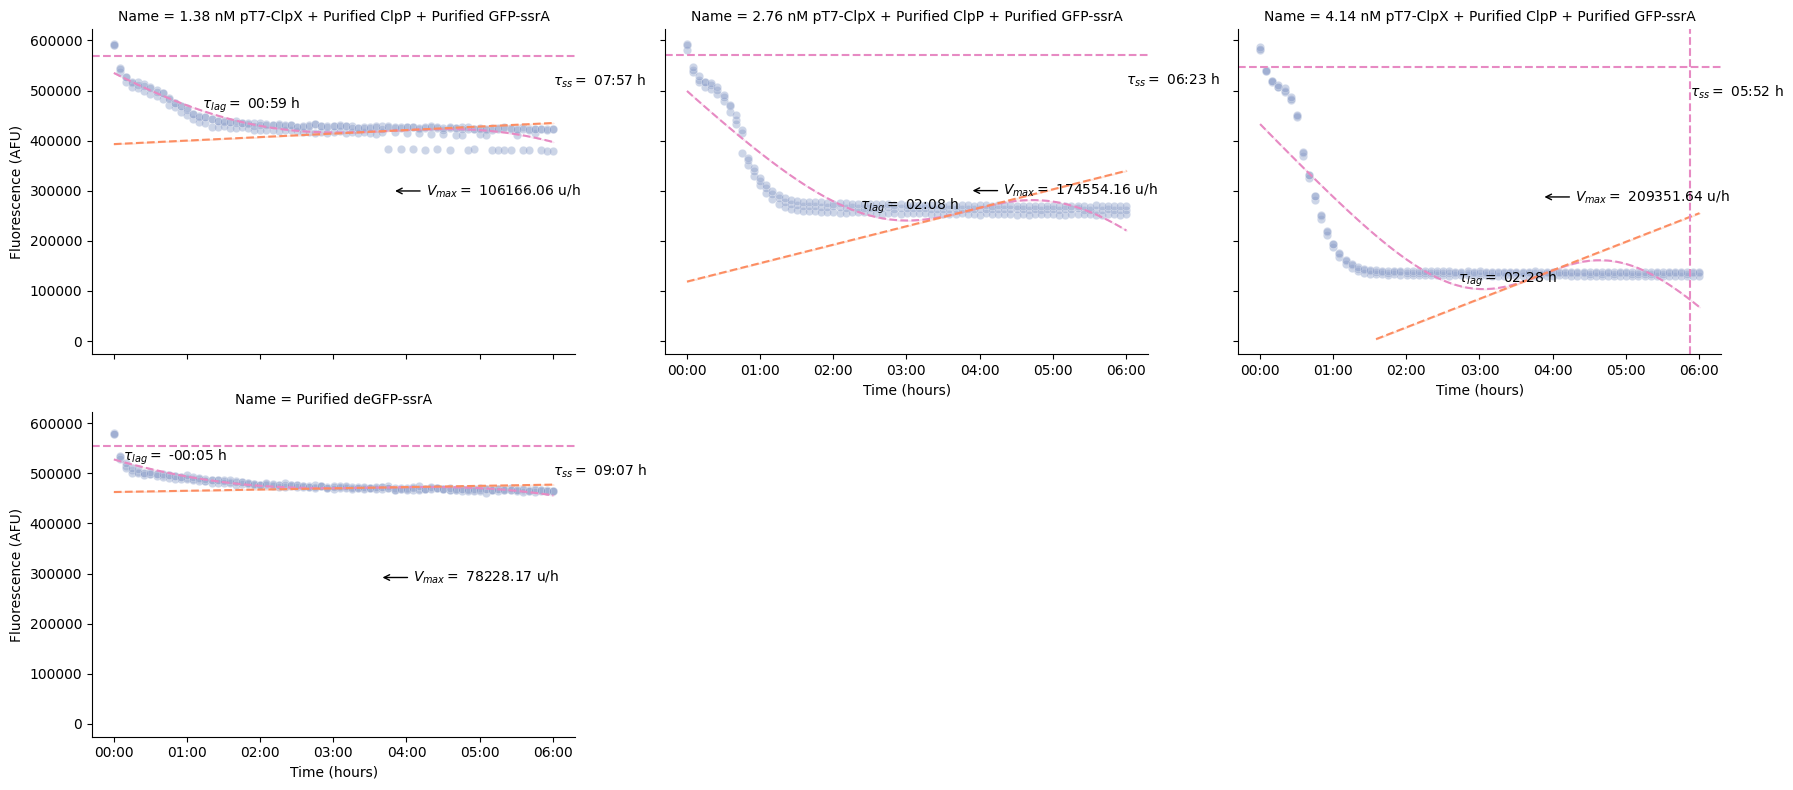

In [8]:
# Plot kinetic fits 
g = pr.plot_kinetics(data, kinetics=kinetics)

## Summary Plots

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


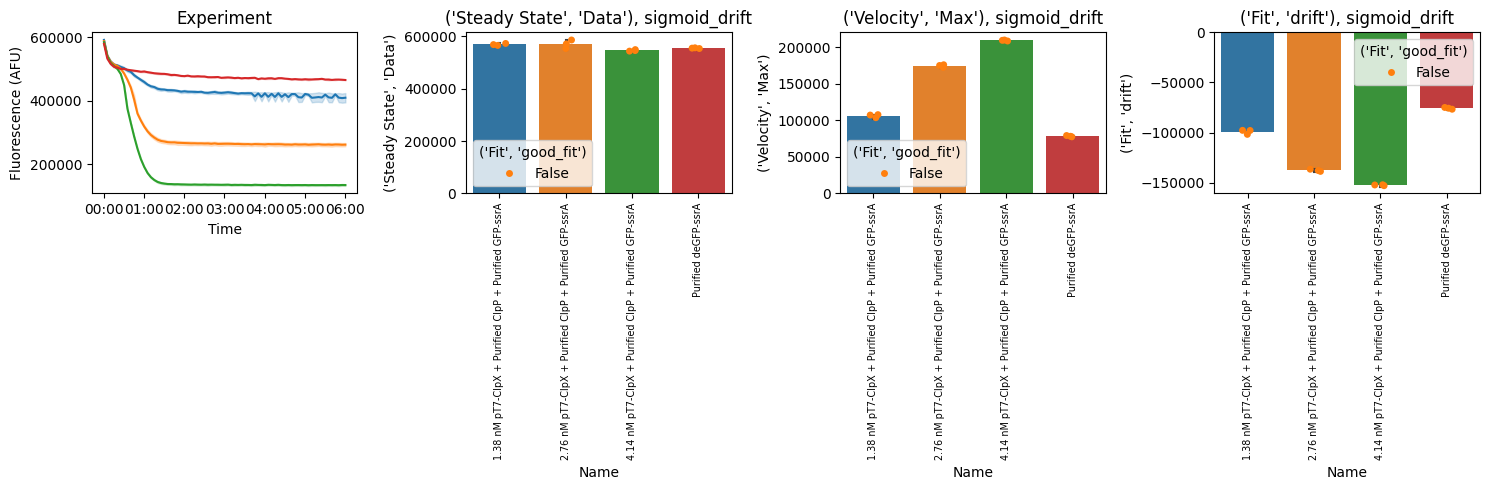

In [9]:
g = pr.plot_summary(data)
# g.savefig("summary.png", dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants